# 04 · Modelling for insight

<sub>Telco churn analysis &nbsp;|&nbsp; 01 Framing · 02 Cleaning & EDA · 03 Hypothesis tests · **04 Modelling** · 05 A/B test & ROI</sub>

**Goal:** learn *which factors matter and by how much*, and produce **calibrated** probabilities for the ROI analysis.

> **Key findings**
>
> - 18 model configurations (incl. tuned boosting, soft voting, stacking) score CV AUC 0.83–0.87; most are tied within noise.
> - The **one-standard-error rule** selects tuned **logistic regression** (CV AUC 0.863 vs best 0.865). Test AUC 0.853.
> - Top drivers (logit and SHAP agree): month-to-month contract, no dependents, short tenure, fiber, e-check.
> - `monthly_charges` is ~100 % explained by services bought, so price acts *through* the product mix.
> - Logistic regression is already well calibrated; naive Bayes and AdaBoost show why that matters.

**Pipeline** (`python train_pipeline.py`, outputs read below):
shared `ColumnTransformer` → 12 model families → `RandomizedSearchCV` on LR / RF / XGBoost / LightGBM → soft-voting and stacking ensembles → one-SE selection → Platt / isotonic calibration check → out-of-fold scores for every customer.

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from churn import config as C, style, charts
style.setup()

In [2]:
import json, joblib
from churn.data_cleaning import load_clean
from churn.metrics import lift_table
from churn.interpretation import fit_logit, lgbm_shap, base_feature

df = load_clean()
cv = pd.read_csv(C.METRICS_DIR / "cv_comparison.csv", index_col=0)
test = pd.read_csv(C.METRICS_DIR / "test_results.csv", index_col=0)
summary = json.loads((C.METRICS_DIR / "summary.json").read_text())
art = joblib.load(C.MODELS_DIR / "evaluation_artifacts.joblib")
X_te, y_te, probs = art["X_test"], art["y_test"], art["test_probs"]
final = summary["final_model"]

## 1 · Model comparison (5-fold CV on the 80 % training split)

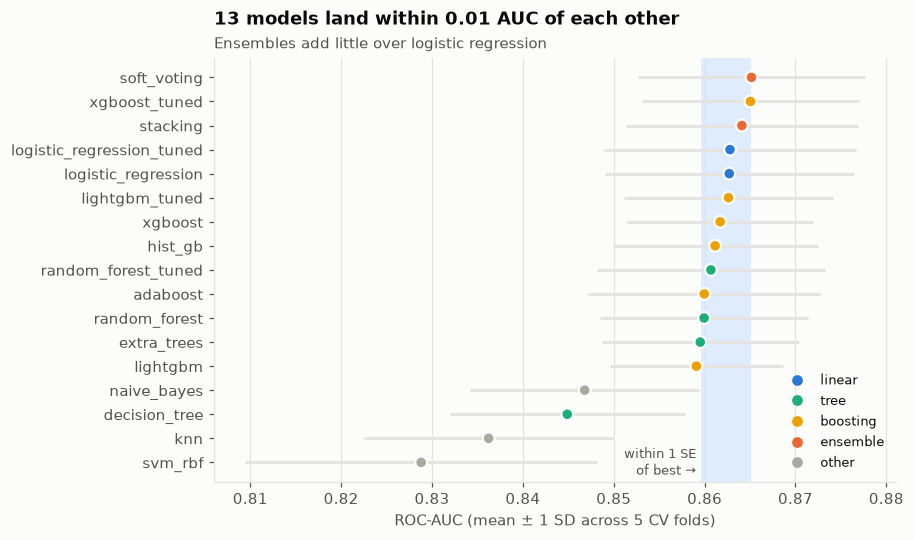

In [3]:
charts.model_comparison(cv);

In [4]:
cols = {"roc_auc": "{:.3f}", "roc_auc_sd": "±{:.3f}", "pr_auc": "{:.3f}", "brier": "{:.3f}", "fit_seconds": "{:.0f}s"}
style.table(cv[list(cols)].head(8), fmt=cols, caption="Top 8 by CV ROC-AUC", highlight=[final])

,roc_auc,roc_auc_sd,pr_auc,brier,fit_seconds
model,,,,,
soft_voting,0.865,±0.012,0.692,0.128,6s
xgboost_tuned,0.865,±0.012,0.691,0.128,0s
stacking,0.864,±0.013,0.691,0.129,96s
logistic_regression_tuned,0.863,±0.014,0.691,0.128,0s
logistic_regression,0.863,±0.014,0.691,0.128,1s
lightgbm_tuned,0.863,±0.012,0.687,0.129,3s
xgboost,0.862,±0.010,0.685,0.130,2s
hist_gb,0.861,±0.011,0.681,0.130,2s


> **Why not pick the top model?** The fold-to-fold SD of AUC (~0.012) is ~5× the gap between soft voting and logistic regression (0.0024). Among statistically tied models we take the **simplest**: easier to explain, cheaper to run, more stable.

In [5]:
test_cols = {"roc_auc": "{:.3f}", "pr_auc": "{:.3f}", "brier": "{:.3f}", "ece": "{:.3f}", "recall": "{:.2f}", "precision": "{:.2f}"}
style.table(test.drop(index=f"{final} + {summary['calibration']}", errors="ignore")[list(test_cols)].head(8),
          fmt=test_cols, caption="Held-out test set (20 %, never used for training or selection)", highlight=[final])

,roc_auc,pr_auc,brier,ece,recall,precision
model,,,,,,
xgboost_tuned,0.860,0.681,0.131,0.026,0.55,0.66
soft_voting,0.859,0.681,0.131,0.021,0.55,0.68
lightgbm_tuned,0.859,0.678,0.131,0.019,0.54,0.68
stacking,0.858,0.677,0.133,0.034,0.55,0.67
hist_gb,0.857,0.673,0.132,0.022,0.54,0.67
random_forest_tuned,0.856,0.669,0.132,0.017,0.53,0.67
lightgbm,0.856,0.673,0.132,0.028,0.54,0.65
random_forest,0.855,0.669,0.132,0.016,0.52,0.67


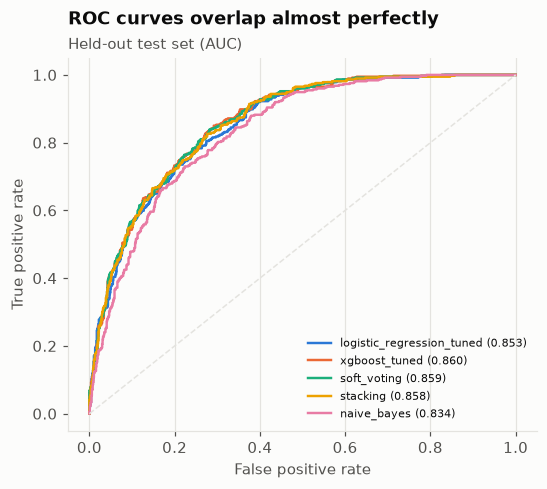

In [6]:
show = ["logistic_regression_tuned", "xgboost_tuned", "soft_voting", "stacking", "naive_bayes"]
charts.roc_curves(y_te, {m: probs[m] for m in show}, test["roc_auc"]);

## 2 · Interpretable model: odds ratios

`statsmodels` logit on all 7,043 customers. `monthly_charges` (VIF ≈ 860, R² = 0.999 from services) and `total_charges` (≈ tenure × monthly) are dropped so the coefficients are meaningful. Reference levels: **DSL**, **month-to-month**, **bank transfer**.

McFadden pseudo-R² = 0.307 · n = 7,043


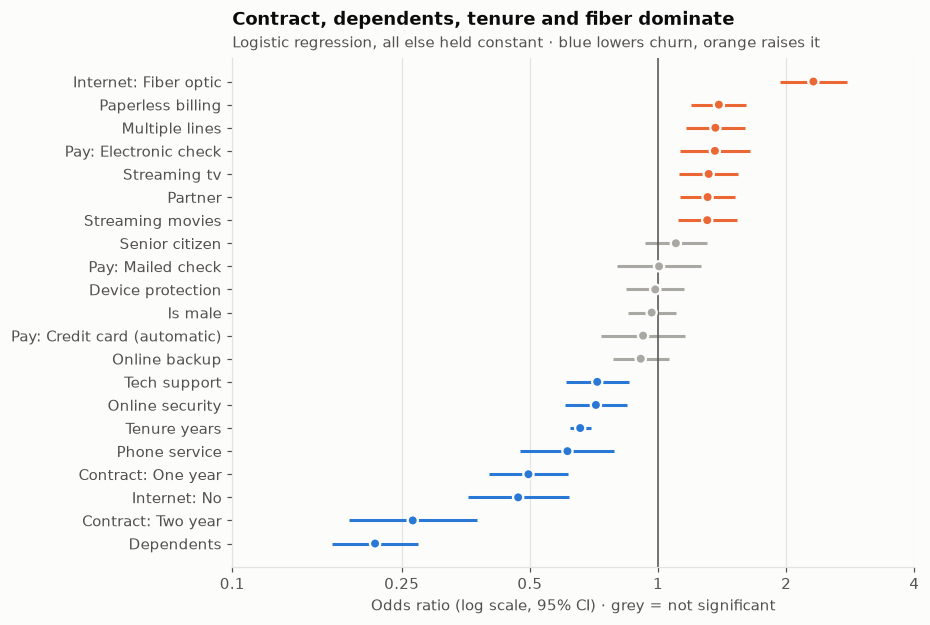

In [7]:
logit, ors = fit_logit(df)
print(f"McFadden pseudo-R² = {logit.prsquared:.3f} · n = {int(logit.nobs):,}")
charts.odds_ratio_forest(ors);

In [8]:
key = ors.loc[["Contract: Two year", "Contract: One year", "Dependents", "Tenure years",
               "Internet: Fiber optic", "Pay: Electronic check", "Online security", "Tech support"]]
key = key.assign(effect=lambda d: [f"{abs(o - 1):.0%} {'higher' if o > 1 else 'lower'} odds" for o in d.odds_ratio])
style.table(key[["odds_ratio", "ci_low", "ci_high", "effect"]],
          fmt={"odds_ratio": "{:.2f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}"}, caption="Key odds ratios")

,odds_ratio,ci_low,ci_high,effect
Contract: Two year,0.27,0.19,0.37,73% lower odds
Contract: One year,0.50,0.40,0.61,50% lower odds
Dependents,0.22,0.17,0.27,78% lower odds
Tenure years,0.66,0.62,0.69,34% lower odds
Internet: Fiber optic,2.32,1.93,2.78,132% higher odds
Pay: Electronic check,1.36,1.13,1.64,36% higher odds
Online security,0.71,0.60,0.85,29% lower odds
Tech support,0.72,0.61,0.85,28% lower odds


> **Reading:** a two-year contract cuts the odds of churn by ~73 %; having dependents by ~78 %; each extra year of tenure by ~34 %. Fiber still more than doubles the odds vs DSL with everything else held fixed. E-check shrinks from OR 4.0 (raw) to 1.4: most of its raw effect was contract mix.

## 3 · Gradient boosting + SHAP

Exact TreeSHAP values from LightGBM's native `pred_contrib` (the `shap` package is blocked by Windows Smart App Control on this machine; the numbers are identical).

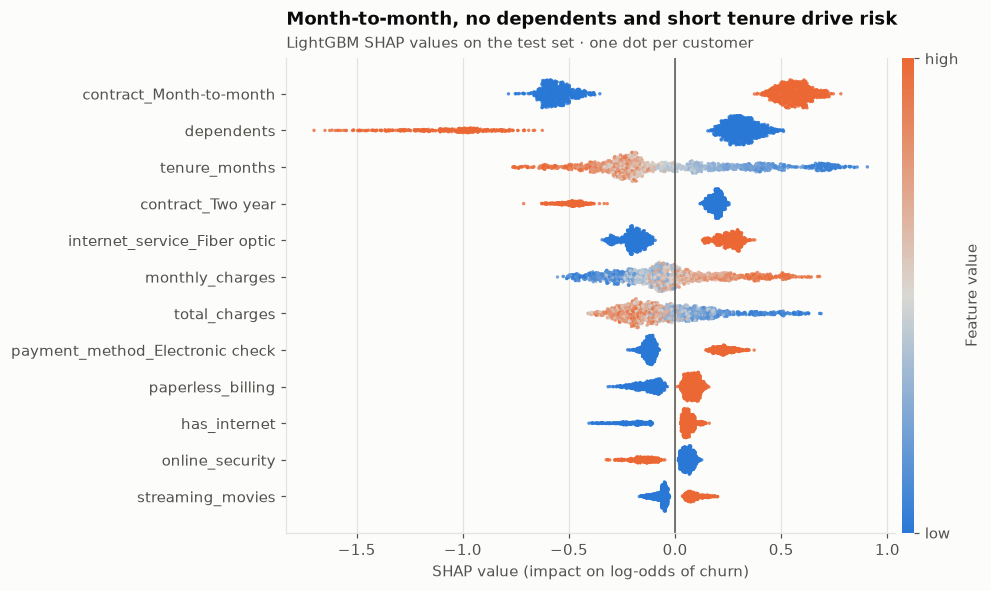

In [9]:
shap, Xt, base = lgbm_shap(art["lightgbm"], X_te)
charts.shap_beeswarm(shap, Xt);

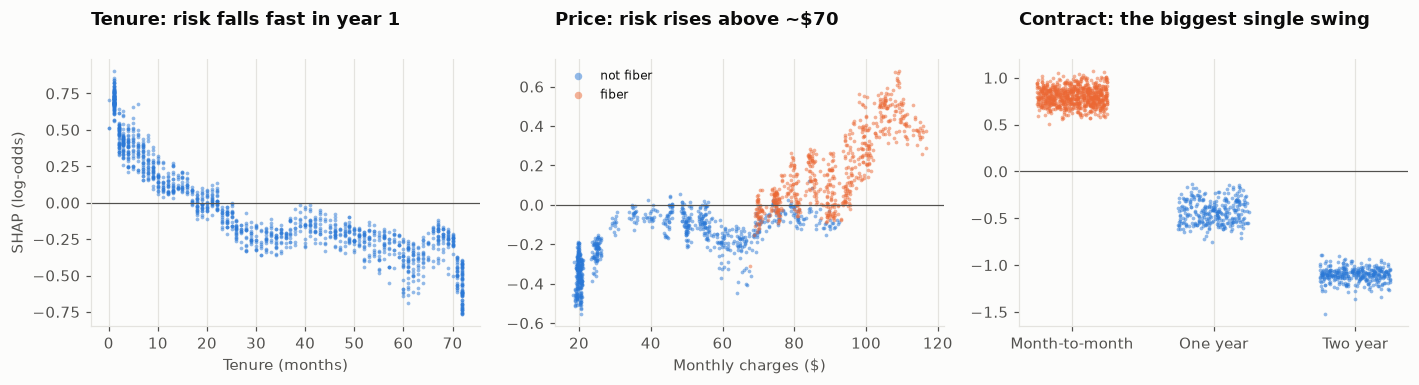

In [10]:
charts.shap_dependence(X_te, shap);

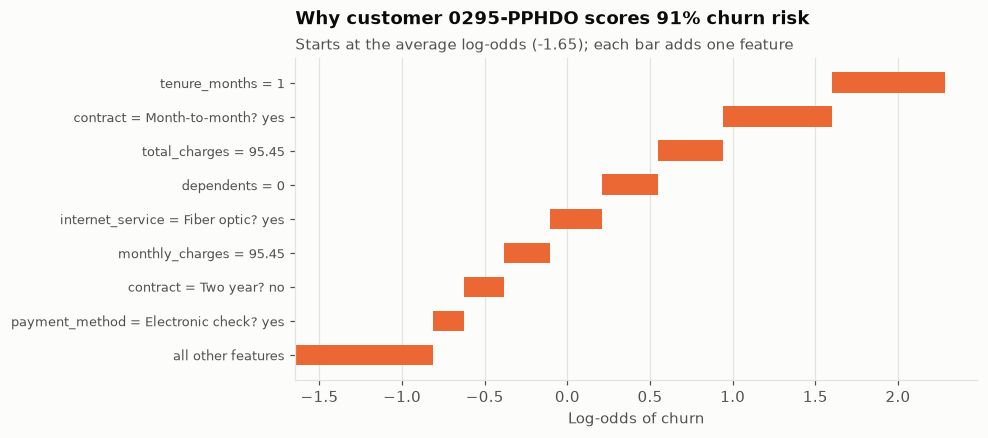

In [11]:
i = int(np.argmax(shap.sum(axis=1)))   # highest-risk customer in the test set
charts.shap_waterfall(shap.iloc[i], X_te.iloc[i], base, df.loc[X_te.index[i], "customer_id"]);

In [12]:
from scipy.stats import spearmanr
shap_rank = shap.abs().T.groupby(base_feature).sum().T.mean().rank(ascending=False)
z = (logit.params / logit.bse).abs().drop("const")
lr_rank = z.groupby([base_feature(c).replace("tenure_years", "tenure_months") for c in z.index]).max().rank(ascending=False)
common = shap_rank.index.intersection(lr_rank.index)
print(f"Agreement between logit and SHAP importance rankings: Spearman ρ = {spearmanr(shap_rank[common], lr_rank[common]).statistic:.2f}")

Agreement between logit and SHAP importance rankings: Spearman ρ = 0.81


## 4 · Calibration: why it matters for the business

Notebook 05 multiplies predicted probabilities by revenue. If the model says 60 % when the truth is 40 %, revenue at risk is overstated by 50 % and an unprofitable discount looks profitable. **AUC can't detect this; calibration can.**

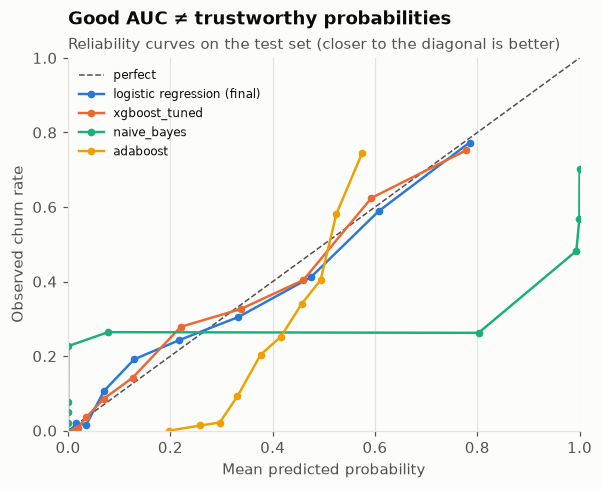

In [13]:
charts.reliability(y_te, {"logistic regression (final)": probs[final], "xgboost_tuned": probs["xgboost_tuned"],
                         "naive_bayes": probs["naive_bayes"], "adaboost": probs["adaboost"]});

In [14]:
cal = pd.read_csv(C.METRICS_DIR / "calibration_choice.csv", index_col=0)
style.table(cal, fmt="{:.4f}", caption=f"Out-of-fold calibration check → chosen: '{summary['calibration']}'")

,brier,ece
method,,
none,0.1282,0.0099
sigmoid,0.1283,0.0101
isotonic,0.1285,0.0081


> Naive Bayes is over-confident; AdaBoost squashes scores toward 0.5. Both rank well but would wreck an ROI estimate. Logistic regression needs no recalibration (Platt and isotonic don't improve its Brier score).

## 5 · From scores to action

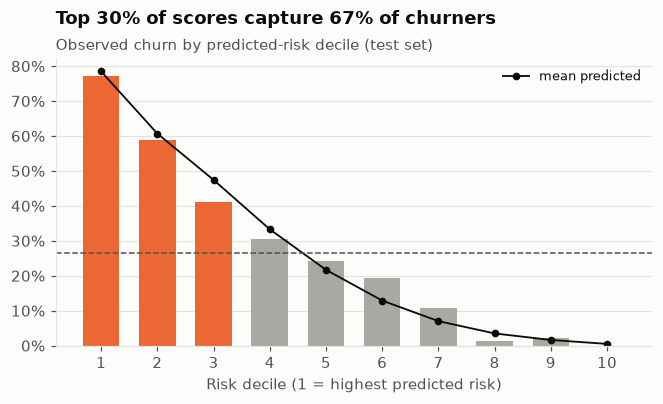

In [15]:
lt = lift_table(y_te, probs[final])
charts.lift(lt, y_te.mean());

In [16]:
style.table(lt[["customers", "churn_rate", "mean_predicted", "lift", "cum_capture"]],
          fmt={"churn_rate": "{:.1%}", "mean_predicted": "{:.1%}", "lift": "{:.2f}×", "cum_capture": "{:.0%}"},
          caption="Lift by risk decile (test set)")

,customers,churn_rate,mean_predicted,lift,cum_capture
decile,,,,,
1,141,77.3%,78.5%,2.91×,29%
2,141,58.9%,60.7%,2.22×,51%
3,141,41.1%,47.4%,1.55×,67%
4,141,30.5%,33.3%,1.15×,78%
5,141,24.1%,21.7%,0.91×,87%
6,140,19.3%,12.9%,0.73×,95%
7,141,10.6%,7.0%,0.40×,99%
8,141,1.4%,3.5%,0.05×,99%
9,141,2.1%,1.6%,0.08×,100%
